# Notebook 01 — Verifikasi Dataset, EDA, dan Preprocessing (Role Data)
**Proyek:** RetenSight  
**Dataset Acuan:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` (Versi: `telco-churn-v1.0`)  

Notebook ini memenuhi checklist **Tugas Pertama** serta **EDA dan preprocessing** pada `docs/jobdesk.md`:
1. Verifikasi dimensi dataset, keunikan `customerID`, dan distribusi target `Churn`.
2. Konversi `TotalCharges` ke numerik, pemeriksaan 11 baris nilai kosong (`tenure == 0`), dan keputusan cleaning.
3. Pemeriksaan kategori khusus (`No internet service`, `No phone service`).
4. Exploratory Data Analysis (EDA): proporsi churn, distribusi masa berlangganan (`tenure`), tagihan (`MonthlyCharges`, `TotalCharges`), serta kontrak dan layanan (lengkap dengan penyebut setiap persentase).
5. Definisi daftar fitur per model (Klasifikasi, Clustering, Regresi), pembagian data 80:20 (`random_state=42`), dan kerangka Pipeline Preprocessing.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)

# Pastikan path bekerja baik dijalankan dari root maupun dari data/notebooks/
ROOT_DIR = Path.cwd()
if not (ROOT_DIR / 'data' / 'raw').exists():
    ROOT_DIR = ROOT_DIR.parent.parent

DATA_PATH = ROOT_DIR / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df_raw = pd.read_csv(DATA_PATH)

print(f'Lokasi file : {DATA_PATH}')
print(f'Jumlah baris: {df_raw.shape[0]:,}')
print(f'Jumlah kolom: {df_raw.shape[1]}')
display(df_raw.head())

Lokasi file : D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Jumlah baris: 7,043
Jumlah kolom: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Verifikasi `customerID`, Konversi `TotalCharges`, dan Keputusan Cleaning

In [2]:
# 1. Periksa customerID kosong atau duplikat
n_rows_before = len(df_raw)
null_id = (df_raw['customerID'].isna() | (df_raw['customerID'].astype(str).str.strip() == '')).sum()
dup_id = df_raw['customerID'].duplicated().sum()

print(f'Jumlah baris SEBELUM cleaning : {n_rows_before:,}')
print(f'customerID kosong             : {null_id}')
print(f'customerID duplikat           : {dup_id}')

# 2. Konversi TotalCharges ke numerik dan periksa nilai kosong (NaN)
df = df_raw.copy()
total_charges_num = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing_tc_mask = total_charges_num.isna()

print(f'\nNilai kosong di TotalCharges setelah konversi ke numerik: {missing_tc_mask.sum()} baris')
display(df.loc[missing_tc_mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

# 3. Keputusan Cleaning:
# Seluruh 11 baris dengan TotalCharges kosong memiliki tenure == 0 bulan (pelanggan baru belum ditagih akumulasi).
# Kita isi nilai NaN pada TotalCharges dengan 0.0 agar seluruh 7.043 pelanggan tetap terjaga.
df['TotalCharges'] = total_charges_num.fillna(0.0)
n_rows_after = len(df)

print(f'Jumlah baris SESUDAH cleaning : {n_rows_after:,} (tidak ada baris yang dibuang)')
print('Tipe data TotalCharges sekarang:', df['TotalCharges'].dtype)

Jumlah baris SEBELUM cleaning : 7,043
customerID kosong             : 0
customerID duplikat           : 0

Nilai kosong di TotalCharges setelah konversi ke numerik: 11 baris


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Jumlah baris SESUDAH cleaning : 7,043 (tidak ada baris yang dibuang)
Tipe data TotalCharges sekarang: float64


## 2. Pemeriksaan Kategori Khusus (`No internet service` & `No phone service`)

In [3]:
cat_cols = [c for c in df.columns if df[c].dtype == 'object' and c != 'customerID']
summary_cat = []
for col in cat_cols:
    uniques = df[col].unique().tolist()
    has_special = [u for u in uniques if 'No ' in str(u)]
    summary_cat.append({
        'Kolom': col,
        'Jumlah Kategori': len(uniques),
        'Daftar Kategori': ', '.join(uniques),
        'Kategori Khusus': ', '.join(has_special) if has_special else '-'
    })

display(pd.DataFrame(summary_cat))

,Kolom,Jumlah Kategori,Daftar Kategori,Kategori Khusus
0,gender,2,"Female, Male",-
1,Partner,2,"Yes, No",-
2,Dependents,2,"No, Yes",-
3,PhoneService,2,"No, Yes",-
4,MultipleLines,3,"No phone service, No, Yes",No phone service
5,InternetService,3,"DSL, Fiber optic, No",-
6,OnlineSecurity,3,"No, Yes, No internet service",No internet service
7,OnlineBackup,3,"Yes, No, No internet service",No internet service
8,DeviceProtection,3,"No, Yes, No internet service",No internet service
9,TechSupport,3,"No, Yes, No internet service",No internet service


## 3. EDA — Distribusi Target `Churn`
Setiap persentase menggunakan penyebut total pelanggan **`N = 7.043`**.

,Jumlah Pelanggan,Penyebut (Total N),Proporsi (%)
Churn,,,
No,5174,7043,73.46
Yes,1869,7043,26.54


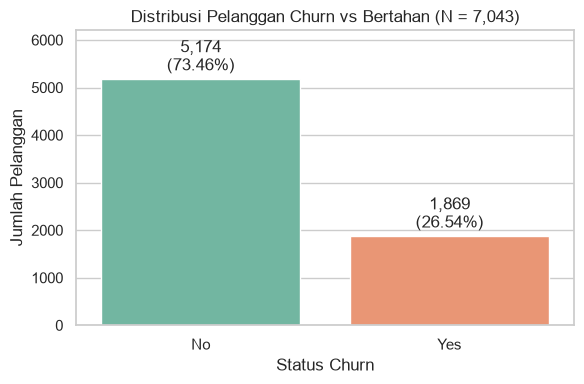

In [4]:
total_customers = len(df)
churn_counts = df['Churn'].value_counts()
churn_summary = pd.DataFrame({
    'Jumlah Pelanggan': churn_counts,
    'Penyebut (Total N)': total_customers,
    'Proporsi (%)': (churn_counts / total_customers * 100).round(2)
})
display(churn_summary)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', legend=False, ax=ax)
ax.set_title(f'Distribusi Pelanggan Churn vs Bertahan (N = {total_customers:,})')
ax.set_xlabel('Status Churn')
ax.set_ylabel('Jumlah Pelanggan')
for container in ax.containers:
    labels = [f'{int(v.get_height()):,}\n({v.get_height()/total_customers*100:.2f}%)' for v in container]
    ax.bar_label(container, labels=labels, padding=3)
ax.set_ylim(0, 6200)
plt.tight_layout()
plt.show()

## 4. EDA — Distribusi Masa Berlangganan (`tenure`) dan Tagihan (`MonthlyCharges` & `TotalCharges`)

Ringkasan Statistik Numerik Keseluruhan (N = 7.043):


,count,mean,std,min,50%,max
tenure,7043.0,32.37,24.56,0.00,29.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,70.35,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,1394.55,8684.80



Ringkasan Statistik Numerik Berdasarkan Status Churn:


tenure                      MonthlyCharges                       \
       count   mean median    std          count   mean median    std   
Churn                                                                   
No      5174  37.57   38.0  24.11           5174  61.27  64.43  31.09   
Yes     1869  17.98   10.0  19.53           1869  74.44  79.65  24.67   

      TotalCharges                             
             count     mean   median      std  
Churn                                          
No            5174  2549.91  1679.52  2329.95  
Yes           1869  1531.80   703.55  1890.82

,Total_Pelanggan,Jumlah_Churn,Penyebut_Total_N,Proporsi_dari_Total_N (%),Churn_Rate_Kelompok (%)
tenure_group,,,,,
0-12 Bulan,2186,1037,7043,31.04,47.44
13-24 Bulan,1024,294,7043,14.54,28.71
25-48 Bulan,1594,325,7043,22.63,20.39
49-72 Bulan,2239,213,7043,31.79,9.51


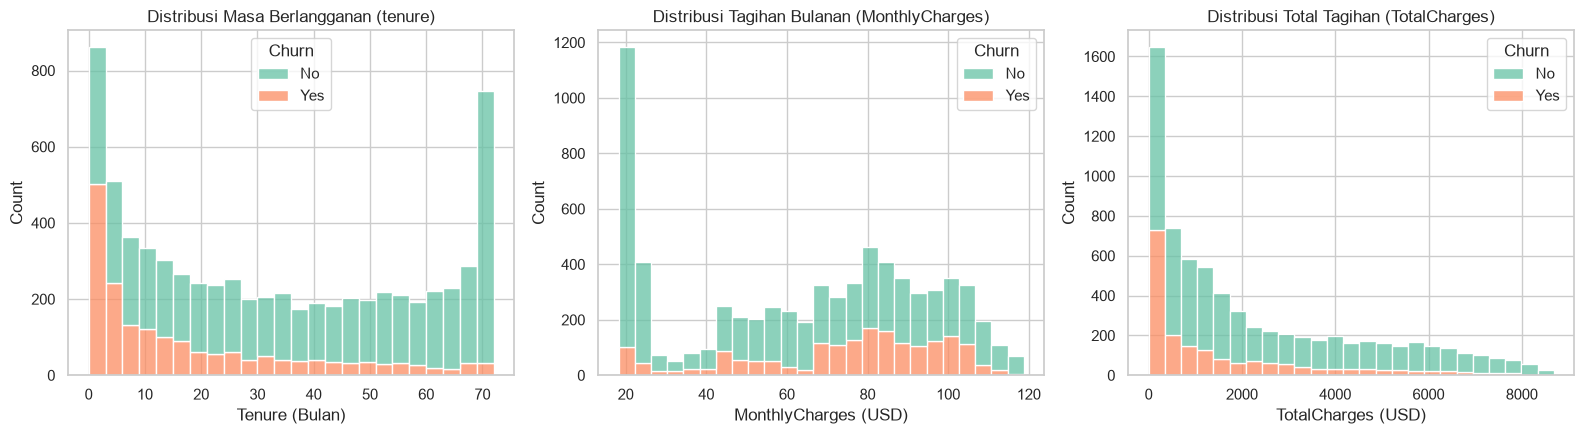

In [5]:
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
desc_overall = df[num_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
desc_by_churn = df.groupby('Churn')[num_features].agg(['count', 'mean', 'median', 'std'])

print('Ringkasan Statistik Numerik Keseluruhan (N = 7.043):')
display(desc_overall.round(2))

print('\nRingkasan Statistik Numerik Berdasarkan Status Churn:')
display(desc_by_churn.round(2))

# Pengelompokan tenure untuk melihat proporsi churn per kelompok masa berlangganan
df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 Bulan', '13-24 Bulan', '25-48 Bulan', '49-72 Bulan']
)
tenure_table = df.groupby('tenure_group', observed=False).agg(
    Total_Pelanggan=('customerID', 'count'),
    Jumlah_Churn=('Churn', lambda s: (s == 'Yes').sum())
)
tenure_table['Penyebut_Total_N'] = total_customers
tenure_table['Proporsi_dari_Total_N (%)'] = (tenure_table['Total_Pelanggan'] / total_customers * 100).round(2)
tenure_table['Churn_Rate_Kelompok (%)'] = (tenure_table['Jumlah_Churn'] / tenure_table['Total_Pelanggan'] * 100).round(2)
display(tenure_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=24, ax=axes[0])
axes[0].set_title('Distribusi Masa Berlangganan (tenure)')
axes[0].set_xlabel('Tenure (Bulan)')

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple='stack', bins=25, ax=axes[1])
axes[1].set_title('Distribusi Tagihan Bulanan (MonthlyCharges)')
axes[1].set_xlabel('MonthlyCharges (USD)')

sns.histplot(data=df, x='TotalCharges', hue='Churn', multiple='stack', bins=25, ax=axes[2])
axes[2].set_title('Distribusi Total Tagihan (TotalCharges)')
axes[2].set_xlabel('TotalCharges (USD)')

plt.tight_layout()
plt.show()
df.drop(columns=['tenure_group'], inplace=True)

## 5. EDA — Distribusi Kontrak (`Contract`) dan Layanan (`InternetService` & Layanan Tambahan)

1. Distribusi Kontrak (Contract):


,Total_Kategori,Churn_Yes,Churn_No,Penyebut_Total_N,Proporsi_Kategori_dari_N (%),Churn_Rate_di_Kategori (%)
Contract,,,,,,
Month-to-month,3875,1655,2220,7043,55.02,42.71
One year,1473,166,1307,7043,20.91,11.27
Two year,1695,48,1647,7043,24.07,2.83



2. Distribusi Layanan Internet (InternetService):


,Total_Kategori,Churn_Yes,Churn_No,Penyebut_Total_N,Proporsi_Kategori_dari_N (%),Churn_Rate_di_Kategori (%)
InternetService,,,,,,
DSL,2421,459,1962,7043,34.37,18.96
Fiber optic,3096,1297,1799,7043,43.96,41.89
No,1526,113,1413,7043,21.67,7.40



3. Distribusi Layanan Telepon (PhoneService):


,Total_Kategori,Churn_Yes,Churn_No,Penyebut_Total_N,Proporsi_Kategori_dari_N (%),Churn_Rate_di_Kategori (%)
PhoneService,,,,,,
No,682,170,512,7043,9.68,24.93
Yes,6361,1699,4662,7043,90.32,26.71


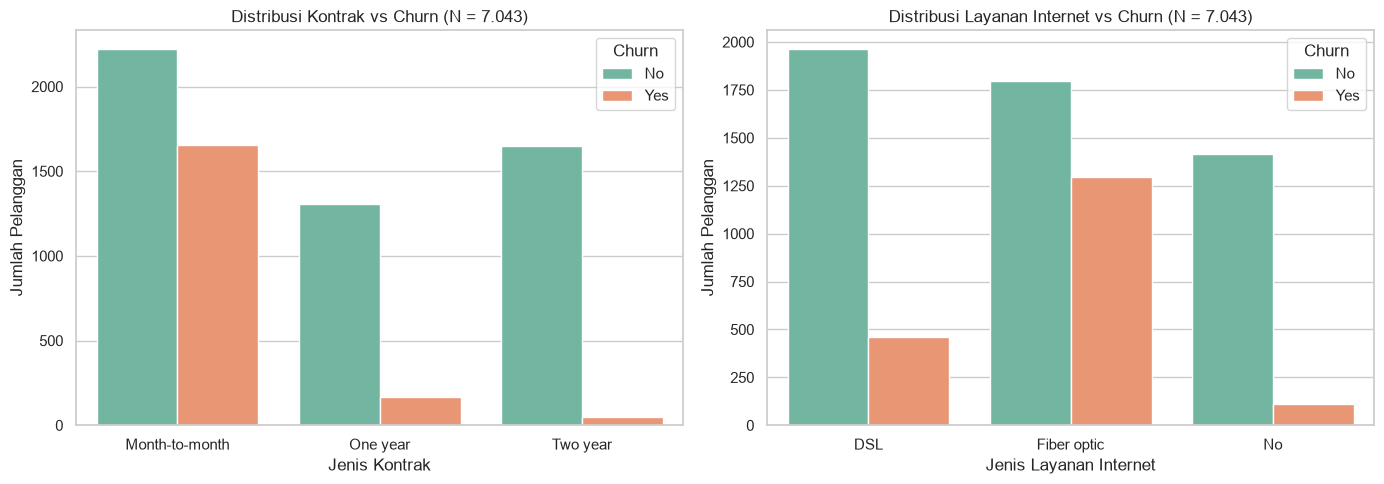

In [6]:
def summarize_categorical(data, col):
    grp = data.groupby(col).agg(
        Total_Kategori=('customerID', 'count'),
        Churn_Yes=('Churn', lambda s: (s == 'Yes').sum()),
        Churn_No=('Churn', lambda s: (s == 'No').sum())
    )
    grp['Penyebut_Total_N'] = len(data)
    grp['Proporsi_Kategori_dari_N (%)'] = (grp['Total_Kategori'] / len(data) * 100).round(2)
    grp['Churn_Rate_di_Kategori (%)'] = (grp['Churn_Yes'] / grp['Total_Kategori'] * 100).round(2)
    return grp

print('1. Distribusi Kontrak (Contract):')
display(summarize_categorical(df, 'Contract'))

print('\n2. Distribusi Layanan Internet (InternetService):')
display(summarize_categorical(df, 'InternetService'))

print('\n3. Distribusi Layanan Telepon (PhoneService):')
display(summarize_categorical(df, 'PhoneService'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0])
axes[0].set_title('Distribusi Kontrak vs Churn (N = 7.043)')
axes[0].set_xlabel('Jenis Kontrak')
axes[0].set_ylabel('Jumlah Pelanggan')

sns.countplot(data=df, x='InternetService', hue='Churn', ax=axes[1])
axes[1].set_title('Distribusi Layanan Internet vs Churn (N = 7.043)')
axes[1].set_xlabel('Jenis Layanan Internet')
axes[1].set_ylabel('Jumlah Pelanggan')

plt.tight_layout()
plt.show()

## 6. Skema Fitur per Model, Pembagian Data 80:20, dan Kerangka Pipeline Preprocessing
- `customerID` dipertahankan sebagai identitas dan dikeluarkan dari seluruh daftar fitur.
- Pembagian data latih dan uji untuk **Klasifikasi** dan **Regresi** memakai rasio **80:20** (`test_size=0.2`, `random_state=42`), dengan stratifikasi berdasarkan `Churn` untuk klasifikasi.
- Pipeline membungkus `SimpleImputer`, `OneHotEncoder(handle_unknown='ignore')`, dan `StandardScaler`.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42

# 1. Daftar fitur per tugas model
ID_COL = 'customerID'
CLF_TARGET = 'Churn'
REG_TARGET = 'MonthlyCharges'

CLF_FEATURES = [c for c in df.columns if c not in [ID_COL, CLF_TARGET]]
CLUSTER_FEATURES = ['tenure', 'MonthlyCharges', 'TotalCharges']
REG_FEATURES = [c for c in df.columns if c not in [ID_COL, CLF_TARGET, REG_TARGET, 'TotalCharges']]

print(f'Fitur Klasifikasi ({len(CLF_FEATURES)} kolom): {CLF_FEATURES}')
print(f'Fitur Clustering  ({len(CLUSTER_FEATURES)} kolom): {CLUSTER_FEATURES}')
print(f'Fitur Regresi     ({len(REG_FEATURES)} kolom): {REG_FEATURES}')

# 2. Pembagian 80:20 untuk Klasifikasi (Stratified berdasarkan Churn)
X_clf = df[CLF_FEATURES]
y_clf = (df[CLF_TARGET] == 'Yes').astype(int)

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf
)

# 3. Pembagian 80:20 untuk Regresi
X_reg = df[REG_FEATURES]
y_reg = df[REG_TARGET]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=SEED
)

print(f'\nKlasifikasi -> Train: {X_clf_train.shape}, Test: {X_clf_test.shape} (Proporsi Churn Train: {y_clf_train.mean()*100:.2f}%, Test: {y_clf_test.mean()*100:.2f}%)')
print(f'Regresi     -> Train: {X_reg_train.shape}, Test: {X_reg_test.shape}')

# 4. Helper pembuat Preprocessor Pipeline (Imputasi + Encoding + Scaling)
def build_preprocessor(feature_cols, scale_numeric=True):
    num_cols = [c for c in feature_cols if df[c].dtype != 'object']
    cat_cols = [c for c in feature_cols if df[c].dtype == 'object']

    num_steps = [('imputer', SimpleImputer(strategy='constant', fill_value=0.0))]
    if scale_numeric:
        num_steps.append(('scaler', StandardScaler()))
    num_pipe = Pipeline(num_steps)

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    transformers = [('num', num_pipe, num_cols)]
    if cat_cols:
        transformers.append(('cat', cat_pipe, cat_cols))

    return ColumnTransformer(transformers=transformers)

# 5. Konfigurasi Cross-Validation 5-Fold
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
print('Preprocessor dan skema 5-Fold Cross-Validation siap digunakan untuk eksperimen!')

Fitur Klasifikasi (19 kolom): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Fitur Clustering  (3 kolom): ['tenure', 'MonthlyCharges', 'TotalCharges']
Fitur Regresi     (17 kolom): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Klasifikasi -> Train: (5634, 19), Test: (1409, 19) (Proporsi Churn Train: 26.54%, Test: 26.54%)
Regresi     -> Train: (5634, 17), Test: (1409, 17)
Preprocessor dan skema 5-Fold Cross-Validation siap digunakan untuk eksperimen!
